# Machine Learning — Assignment 2

**Fateme Roshani**  
Student ID: 810104151

Parzen-window estimation, kernel classification, Gaussian maximum likelihood, and ridge regression.

## Setup and imports

### Load NumPy, Matplotlib, and SciPy dependencies

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## Question 1 — Parzen-window density estimation

### Implement the piecewise Parzen-window mean

In [ ]:
def parzen_density_estimation(h_n, x):

  x = np.array(x)
  y = np.zeros_like(x, dtype=float)

  mask_neg = x <= 0
  mask_mid = (x > 0) & (x <= a)
  mask_high = x > a

  y[mask_mid] = (1.0/a) * (1 - np.exp(-x[mask_mid]/h_n))
  y[mask_high] = (1.0/a) * (np.exp(a/h_n) - 1) * (np.exp(-x[mask_high]/h_n))

  return y

### Define the evaluation grid and bandwidths

In [ ]:
x = np.linspace(-1, 2 , 1000)
hs = [1.0, 0.25, 0.0625]
a = 1

### Compare Parzen estimates for three bandwidths

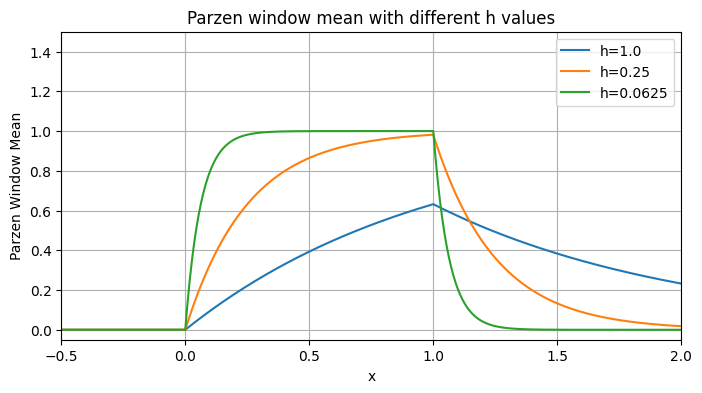

In [ ]:
plt.figure(figsize=(8,4))
for h_n in hs:
  plt.plot(x, parzen_density_estimation(h_n, x), label=f'h={h_n}')

plt.xlim(-0.5,2)
plt.ylim(-0.05,1.5)
plt.xlabel('x')
plt.ylabel('Parzen Window Mean')
plt.title('Parzen window mean with different h values')
plt.legend()
plt.grid(True)
plt.show()

### Inspect the small-bandwidth estimate near zero

/tmp/ipython-input-3507883064.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


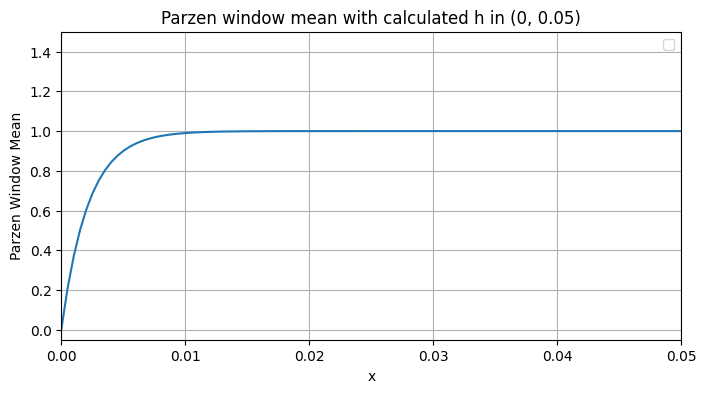

In [ ]:
a = 1
hs = 0.0021714724
x = np.linspace(0, 0.05, 100)

plt.figure(figsize=(8,4))
plt.plot(x, parzen_density_estimation(hs, x))

plt.xlim(0,0.05)
plt.ylim(-0.05,1.5)
plt.xlabel('x')
plt.ylabel('Parzen Window Mean')
plt.title('Parzen window mean with calculated h in (0, 0.05)')
plt.legend()
plt.grid(True)
plt.show()

---


## Question 10 — Gaussian-kernel classification

### Training dataset

### Define labeled three-dimensional training samples

In [3]:
w1 = np.array([
    [0.28, 1.31, -6.2],
    [0.07, 0.58, -0.78],
    [1.54, 2.01, -1.63],
    [-0.44, 1.18, -4.32],
    [-0.81, 0.21, 5.73],
    [1.52, 3.16, 2.77],
    [2.20, 2.42, -0.19],
    [0.91, 1.94, 6.21],
    [0.65, 1.93, 4.38],
    [-0.26, 0.82, -0.96],
])

w2 = np.array([
    [0.011, 1.03, -0.21],
    [1.27, 1.28, 0.08],
    [0.13, 3.12, 0.16],
    [-0.21, 1.23, -0.11],
    [-2.18, 1.39, -0.19],
    [0.34, 1.96, -0.16],
    [-1.38, 0.94, 0.45],
    [-0.12, 0.82, 0.17],
    [-1.44, 2.31, 0.14],
    [0.26, 1.94, 0.08],
])

w3 = np.array([
    [1.36, 2.17, 0.14],
    [1.41, 1.45, -0.38],
    [1.22, 0.99, 0.69],
    [2.46, 2.19, 1.31],
    [0.68, 0.79, 0.87],
    [2.51, 3.22, 1.35],
    [2.60, 2.44, 0.92],
    [0.64, 0.13, 0.97],
    [0.85, 0.58, 0.99],
    [0.66, 0.51, 0.88],
])

### Parzen-window classifier

### Implement Gaussian-kernel class scores and the classifier

In [5]:
classes = [w1, w2, w3]

def parzen_sum(x, data, h):
  diffs = data - x
  r2 = np.sum(diffs**2, axis=1)
  return np.sum(np.exp(-r2 / (2*h*h)))

def classify(x, h):
  sums = [parzen_sum(x, c, h) for c in classes]
  label = 1 + int(np.argmax(sums))
  return label, sums

tests = [
  np.array([0.50, 1.0, 0.0]),
  np.array([0.31, 1.51, -0.50]),
  np.array([-0.3, 0.44, -0.1]),
]


### Test observations and predicted classes

### Classify test samples at two bandwidths

In [6]:
for h in [1.0, 0.1]:
  print(f"\nh = {h}")
  for x in tests:
    label, sums = classify(x, h)
    print("x =", x)
    print("Sums are:")
    for num in sums:
      print(float(num))
    print(" -> class ω", label, sep="")
  print("-----------")


h = 1.0
x = [0.5 1.  0. ]
Sums are:
1.2591897997233061
4.710784993854763
3.7746557035068116
 -> class ω2
x = [ 0.31  1.51 -0.5 ]
Sums are:
1.5343855472566377
4.827963275034261
2.050403178919641
 -> class ω2
x = [-0.3   0.44 -0.1 ]
Sums are:
1.3990811894977488
3.782543279501114
1.7706635724728121
 -> class ω2
-----------

h = 0.1
x = [0.5 1.  0. ]
Sums are:
8.77469530673296e-22
6.769019526350557e-07
8.000188850603628e-19
 -> class ω2
x = [ 0.31  1.51 -0.5 ]
Sums are:
2.8711163529583766e-22
1.200183821939926e-07
2.1593289688030122e-27
 -> class ω2
x = [-0.3   0.44 -0.1 ]
Sums are:
3.63712276104245e-14
3.7830940387857954e-06
1.0640260760706518e-41
 -> class ω2
-----------


---

## Question 11 — Gaussian maximum-likelihood estimation

### Estimate Gaussian mean and variance (closed form and numerical MLE)

In [10]:
with open("normal.data.txt", "r") as f:
  x = f.read().split()

n = len(x)
x = np.array(x, dtype=float).reshape(1, n)

mu_hat = x.mean()
sig2_hat = np.mean((x - mu_hat)**2)

def nll(theta):
  mu, log_sig2 = theta
  sig2 = np.exp(log_sig2)
  return 0.5*n*np.log(2*np.pi) + 0.5*n*np.log(sig2) + 0.5*np.sum((x-mu)**2)/sig2

res = minimize(nll, x0=[mu_hat, np.log(sig2_hat)])
mu_num = res.x[0]
sig2_num = np.exp(res.x[1])

print("Closed-form:", mu_hat, sig2_hat)
print("Numerical  :", mu_num, sig2_num)
print("success:", res.success)


Closed-form: 100.48049999999999 216.31846975
Numerical  : 100.48049999999999 216.31846975000008
success: True


---

## Question 12 — Gaussian basis regression with ridge regularization

### Part 1 — Generate synthetic noisy observations

### Generate noisy samples from the sinc function

In [11]:
def true_function(x):
  return np.sinc(3 * x)

def generate_dataset(n=25, noise_var=0.01, rng=None):
  if rng is None:
    rng = np.random.default_rng()
  x = rng.uniform(0.0, 1.0, size=n)
  eps = rng.normal(loc=0.0, scale=np.sqrt(noise_var), size=n)
  y = true_function(x) + eps
  return x, y

### Part 2 — Construct Gaussian basis functions and ridge estimator

### Implement Gaussian basis features and ridge regression

In [12]:
def gaussian_design_matrix(x, means, var):
  x = np.asarray(x).reshape(-1, 1)
  means = np.asarray(means).reshape(1, -1)
  gauss = np.exp(-((x - means)**2) / (2.0 * var))
  Phi = np.concatenate([np.ones((x.shape[0], 1)), gauss], axis=1)
  return Phi

def regress_gauss(x, y, means, var, lam, regularize_bias=False):
  Phi = gaussian_design_matrix(x, means, var)
  n_params = Phi.shape[1]

  R = np.eye(n_params)
  if not regularize_bias:
    R[0, 0] = 0.0

  A = Phi.T @ Phi + lam * R
  b = Phi.T @ y
  beta = np.linalg.solve(A, b)
  return beta

def predict(x, means, var, beta):
  Phi = gaussian_design_matrix(x, means, var)
  return Phi @ beta


### Set basis centers, width, and regularization strengths

In [13]:
d = 21
means = np.linspace(0.0, 1.0, d)
sigma = 0.04
var = sigma**2
lambdas_part3 = [0.001, 0.05, 5.0]

### Part 3 — Compare regression fits across regularization levels

### Plot single-dataset and 100-run average regression fits

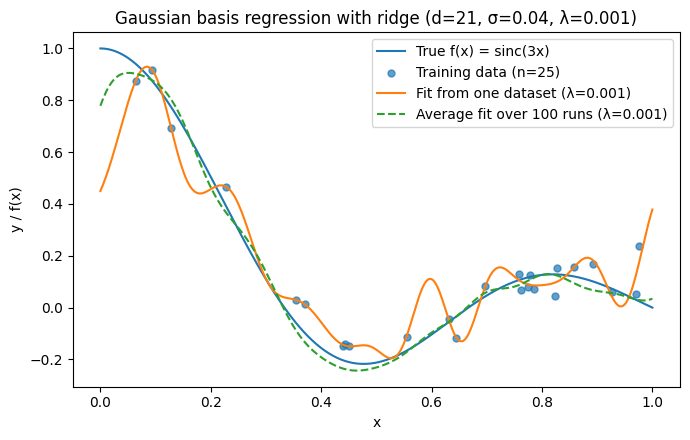

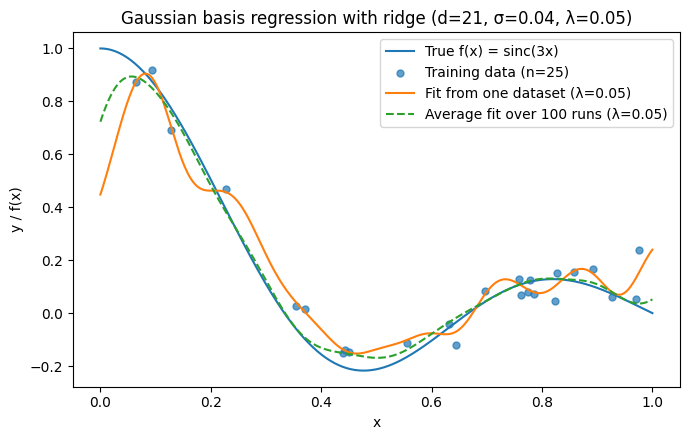

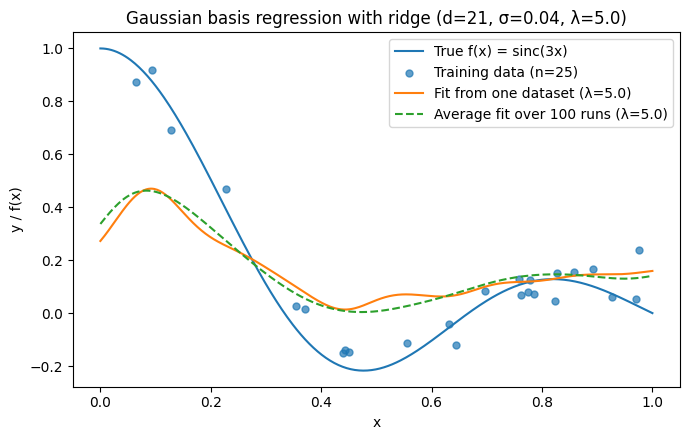

In [14]:
rng = np.random.default_rng(42)
x_train, y_train = generate_dataset(n=25, noise_var=0.01, rng=rng)

x_grid = np.linspace(0.0, 1.0, 400)
f_true = true_function(x_grid)

for lam in lambdas_part3:
  beta_single = regress_gauss(x_train, y_train, means, var, lam)
  f_single = predict(x_grid, means, var, beta_single)

  betas = []
  for _ in range(100):
      x_i, y_i = generate_dataset(n=25, noise_var=0.01, rng=rng)
      betas.append(regress_gauss(x_i, y_i, means, var, lam))
  beta_avg = np.mean(np.stack(betas, axis=0), axis=0)
  f_avg = predict(x_grid, means, var, beta_avg)

  plt.figure(figsize=(7, 4.5))
  plt.plot(x_grid, f_true, label="True f(x) = sinc(3x)")
  plt.scatter(x_train, y_train, s=25, label="Training data (n=25)", alpha=0.7)
  plt.plot(x_grid, f_single, label=f"Fit from one dataset (λ={lam})")
  plt.plot(x_grid, f_avg, label=f"Average fit over 100 runs (λ={lam})", linestyle="--")
  plt.xlabel("x")
  plt.ylabel("y / f(x)")
  plt.title(f"Gaussian basis regression with ridge (d={d}, σ={sigma}, λ={lam})")
  plt.legend()
  plt.tight_layout()
  plt.show()


### Part 4 — Evaluate error as a function of regularization

### Estimate average prediction error and select the best ridge penalty

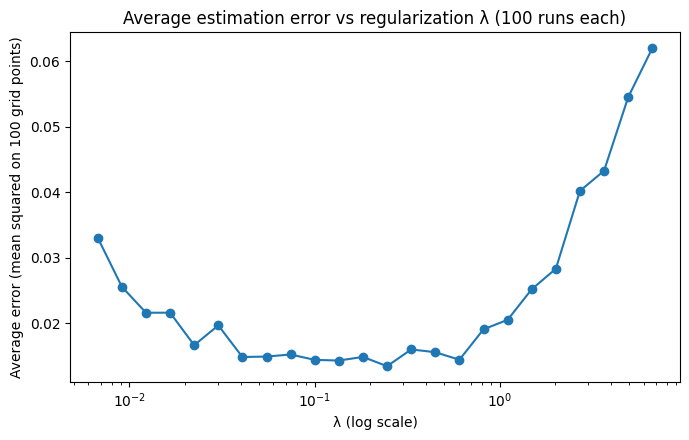

Minimum average error: 0.013450496142847112
Achieved at λ = 0.24659696394160596


In [16]:
lambda_grid = np.exp(np.arange(-5.0, 2.0 + 1e-9, 0.3))
m = 100
z = np.linspace(0.0, 1.0, m)
fz = true_function(z)

def average_error_for_lambda(lam, runs=100, rng=None):
  if rng is None:
    rng = np.random.default_rng()
  errs = []
  for _ in range(runs):
    x_i, y_i = generate_dataset(n=25, noise_var=0.01, rng=rng)
    beta_i = regress_gauss(x_i, y_i, means, var, lam)
    fhat = predict(z, means, var, beta_i)
    err = np.mean((fz - fhat)**2)
    errs.append(err)
  return float(np.mean(errs))

rng_err = np.random.default_rng(123)
avg_errs = np.array([average_error_for_lambda(lam, runs=100, rng=rng_err) for lam in lambda_grid])

plt.figure(figsize=(7, 4.5))
plt.semilogx(lambda_grid, avg_errs, marker='o')
plt.xlabel("λ (log scale)")
plt.ylabel("Average error (mean squared on 100 grid points)")
plt.title("Average estimation error vs regularization λ (100 runs each)")
plt.tight_layout()
plt.show()

best_idx = np.argmin(avg_errs)
print("Minimum average error:", avg_errs[best_idx])
print("Achieved at λ =", lambda_grid[best_idx])